In [1]:
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8-whitegrid')
plt.rc('figure', autolayout=True)
plt.rc('axes', labelweight='bold', labelsize='large',
       titleweight='bold', titlesize=18, titlepad=10)
plt.rc('animation', html='html5')

In [2]:
import pandas as pd

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import make_column_transformer
from sklearn.model_selection import GroupShuffleSplit
from tensorflow.keras import Sequential, callbacks, layers

spotify = pd.read_csv('../datasets/dl-course-data/spotify.csv')

X = spotify.copy().dropna()
y = X.pop('track_popularity')

artists = X['track_artist']
features_num = ['danceability', 'energy', 'key', 'loudness', 'mode',
                'speechiness', 'acousticness', 'instrumentalness',
                'liveness', 'valence', 'tempo', 'duration_ms']
features_cat = ['playlist_genre']

preprocessor = make_column_transformer(
    (StandardScaler(), features_num),
    (OneHotEncoder(), features_cat),
)

# We'll do a "grouped" split to keep all of an artist's songs in one
# split or the other. This is to help prevent signal leakage.
def group_split(X, y, group, train_size=0.75):
    splitter = GroupShuffleSplit(train_size=train_size)
    train, test = next(splitter.split(X, y, groups=group))
    return (X.iloc[train], X.iloc[test], y.iloc[train], y.iloc[test])

X_train, X_valid, y_train, y_valid = group_split(X, y, artists)

X_train = preprocessor.fit_transform(X_train)
y_train = y_train / 100 # popularity is on a scale 0-100, so this rescales to 0-1.

X_valid = preprocessor.transform(X_valid)
y_valid = y_valid / 100

INPUT_SHAPE = [X_train.shape[1]]
print(f"Input shape: {INPUT_SHAPE}")

2025-01-22 22:14:22.626135: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2025-01-22 22:14:22.634895: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2025-01-22 22:14:22.653011: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1737584062.683063   14047 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1737584062.692835   14047 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2025-01-22 22:14:22.730398: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU ins

Input shape: [18]


2025-01-22 22:14:26.443833: E external/local_xla/xla/stream_executor/cuda/cuda_driver.cc:152] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Minimum Validation Loss: 0.1954


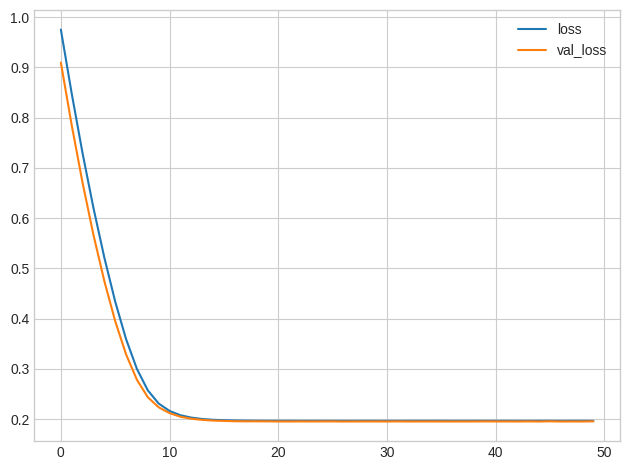

In [3]:
OUTPUT_SHAPE = 1

model = Sequential([
    layers.Input(shape=INPUT_SHAPE),
    layers.Dense(OUTPUT_SHAPE),
])

model.compile(
    optimizer='adam',
    loss='mae',
)

history = model.fit(
    X_train, y_train,
    validation_data=(X_valid, y_valid),
    batch_size=512,
    epochs=50,
    verbose=0,
)

history_df = pd.DataFrame(history.history)
history_df.loc[0:, ['loss', 'val_loss']].plot()
print(f"Minimum Validation Loss: {history_df['val_loss'].min():0.4f}");

Minimum Validation Loss: 0.1954


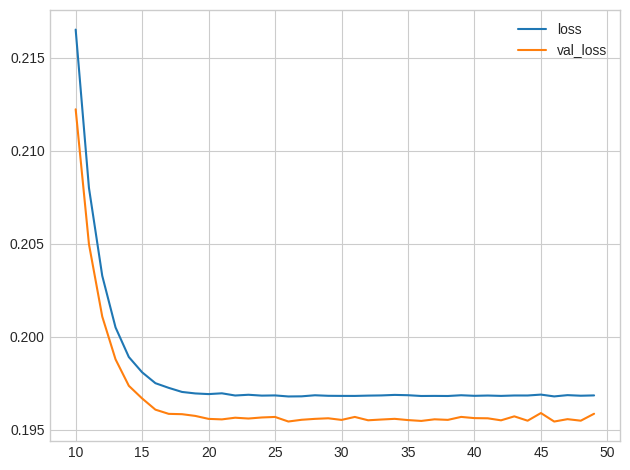

In [4]:
history_df.loc[10:, ['loss', 'val_loss']].plot() # Start the plot at epoch 10
print(f"Minimum Validation Loss: {history_df['val_loss'].min():0.4f}");

In [5]:
from IPython.display import display, Markdown

content = f"""
**Q**: **Would you say this model is underfitting, overfitting, just right?**<br>
**A**:The gap between these curves is quite small and the validation loss never increases, 
so it's more likely that the network is underfitting than overfitting. It would be worth 
experimenting with more capacity to see if that's the case.
"""

display(Markdown(content))


**Q**: **Would you say this model is underfitting, overfitting, just right?**<br>
**A**:The gap between these curves is quite small and the validation loss never increases, 
so it's more likely that the network is underfitting than overfitting. It would be worth 
experimenting with more capacity to see if that's the case.


Epoch 1/50
48/48 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - loss: 0.3862 - val_loss: 0.2111
Epoch 2/50
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.2063 - val_loss: 0.2027
Epoch 3/50
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.1997 - val_loss: 0.1986
Epoch 4/50
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.1977 - val_loss: 0.1977
Epoch 5/50
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.1933 - val_loss: 0.1961
Epoch 6/50
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.1912 - val_loss: 0.1967
Epoch 7/50
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.1899 - val_loss: 0.1953
Epoch 8/50
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.1902 - val_loss: 0.1949
Epoch 9/50
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.1866 - val_loss: 0.1953
Epoch 10/50
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.1851 - val_loss: 0.1972
Epoch 11/50
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.1871 - val_loss: 0.1957
Epoch 12/50
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.1863 - val

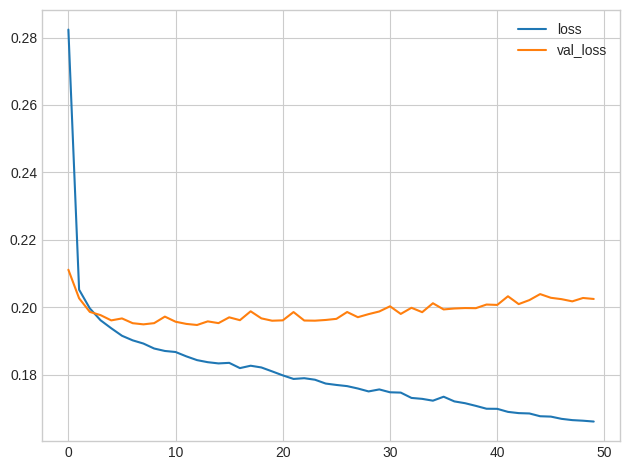

In [6]:
HIDDEN_SHAPE_1, HIDDEN_SHAPE_2 = 128, 64
ReLU = 'relu'

model = Sequential([
    layers.Input(shape=INPUT_SHAPE),
    layers.Dense(HIDDEN_SHAPE_1, activation=ReLU),
    layers.Dense(HIDDEN_SHAPE_2, activation=ReLU),
    layers.Dense(OUTPUT_SHAPE)
])

model.compile(
    optimizer='adam',
    loss='mae',
)

history = model.fit(
    X_train, y_train,
    validation_data=(X_valid, y_valid),
    batch_size=512,
    epochs=50,
)
history_df = pd.DataFrame(history.history)
history_df.loc[:, ['loss', 'val_loss']].plot()
print(f"Minimum Validation Loss: {history_df['val_loss'].min():0.4f}");

In [7]:
content = f"""
**Q**: **What is your evaluation of these curves? Underfitting, overfitting, just right?**<br>
**A**: The validation loss begins to rise very early, while the training loss continues to 
decrease. This indicates that the network has begun to overfit. At this point, we would need to 
try something to prevent it, either by reducing the number of units or through a method like early 
stopping.
"""

display(Markdown(content))


**Q**: **What is your evaluation of these curves? Underfitting, overfitting, just right?**<br>
**A**: The validation loss begins to rise very early, while the training loss continues to 
decrease. This indicates that the network has begun to overfit. At this point, we would need to 
try something to prevent it, either by reducing the number of units or through a method like early 
stopping.


In [8]:
# Define an early stopping callback that waits 5 epochs (patience') 
# for a change in validation loss of at least 0.001 (min_delta) and 
# keeps the weights with the best loss (restore_best_weights).
early_stopping = callbacks.EarlyStopping(
    min_delta=0.001,
    patience=5,
    restore_best_weights=True,
)

Epoch 1/50
48/48 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - loss: 0.3190 - val_loss: 0.2066
Epoch 2/50
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.2038 - val_loss: 0.1999
Epoch 3/50
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.1969 - val_loss: 0.1975
Epoch 4/50
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.1942 - val_loss: 0.1958
Epoch 5/50
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.1896 - val_loss: 0.1963
Epoch 6/50
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.1899 - val_loss: 0.1947
Epoch 7/50
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.1873 - val_loss: 0.1957
Epoch 8/50
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.1862 - val_loss: 0.1953
Epoch 9/50
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.1844 - val_loss: 0.1971
Epoch 10/50
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.1854 - val_loss: 0.1989
Epoch 11/50
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.1857 - val_loss: 0.1954
Minimum Validation Loss: 0.1947


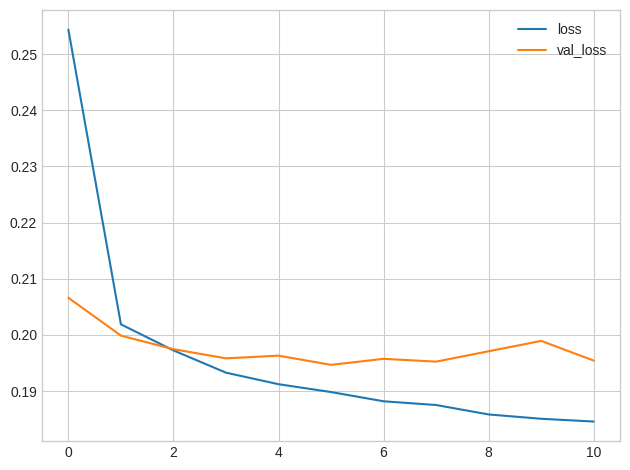

In [11]:
model = Sequential([
    layers.Input(shape=INPUT_SHAPE),
    layers.Dense(units=HIDDEN_SHAPE_1, activation=ReLU),
    layers.Dense(units=HIDDEN_SHAPE_1, activation=ReLU),    
    layers.Dense(OUTPUT_SHAPE)
])

model.compile(
    optimizer='adam',
    loss='mae',
)

history = model.fit(
    X_train, y_train,
    validation_data=(X_valid, y_valid),
    batch_size=512,
    epochs=50,
    callbacks=[early_stopping]
)

history_df = pd.DataFrame(history.history)
history_df.loc[:, ['loss', 'val_loss']].plot()

print(f"Minimum Validation Loss: {history_df['val_loss'].min():0.4f}");

In [13]:
content = f"""
**Q**: **Was this an improvement compared to training without early stopping?**<br>
**A**: The early stopping callback did stop the training once the network began overfitting.
Moreover, by including restore_best_weights we still get to keep the model where validation
loss was lowest.
"""
display(Markdown(content))


**Q**: **Was this an improvement compared to training without early stopping?**<br>
**A**: The early stopping callback did stop the training once the network began overfitting.
Moreover, by including restore_best_weights we still get to keep the model where validation
loss was lowest.
